In [1]:
import pandas as pd

df1 = pd.read_csv("Data/cards_data.csv")
df2 = pd.read_csv("Data/customer_data.csv")
df3 = pd.read_csv("Data/merchant_data.csv")
df4 = pd.read_csv("Data/transaction_data.csv")

In [2]:
df1.columns

Index(['Card_ID', 'Customer_ID', 'Card_Type', 'Card_Network', 'Credit_Limit',
       'Card_Status', 'Contactless', 'Card_Mode', 'Issue_Date', 'Expiry_Date'],
      dtype='object')

In [3]:
df2.columns

Index(['Customer_ID', 'Customer_Name', 'Gender', 'Age', 'Marital_Status',
       'Occupation', 'Annual_Income', 'Customer_Segment', 'State', 'City',
       'Account_Type', 'Customer_Since'],
      dtype='object')

In [4]:
df3.columns

Index(['Merchant_ID', 'Merchant_Name', 'Merchant_Category', 'State', 'City',
       'Merchant_Risk_Level', 'Merchant_Rating', 'Merchant_Status',
       'Merchant_Since'],
      dtype='object')

In [5]:
df4.columns

Index(['Transaction_ID', 'Customer_ID', 'Card_ID', 'Merchant_ID',
       'Transaction_Date', 'Transaction_Time', 'Transaction_Amount',
       'Payment_Method', 'Transaction_Channel', 'Device_Type',
       'Transaction_Status', 'Is_International', 'Fraud_Flag', 'Fraud_Reason',
       'Merchant_Risk_Level', 'Merchant_Category', 'Customer_State',
       'Customer_City', 'Merchant_State', 'Merchant_City'],
      dtype='object')

In [6]:
df5 = pd.merge(df1, df2, on="Customer_ID")
df6 = pd.merge(df5,df4, on = "Customer_ID")
df = pd.merge(df6,df3, on= "Merchant_ID")
df.shape

(384001, 48)

In [7]:
X = df.drop(["Fraud_Flag",
    "Card_ID_x",
    "Customer_ID",
    "Transaction_ID",
    "Card_ID_y",
    "Issue_Date",
    "Expiry_Date",
    "Customer_Since",
    "Transaction_Date",
    "Transaction_Time",
    "Merchant_Since"
], axis=1)

y = df["Fraud_Flag"]

print(X.shape)
print(y.shape)

(384001, 37)
(384001,)


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2)

print(X_train.shape)
print(y_train.shape)

(307200, 37)
(307200,)


In [9]:
cat_features = X_train.select_dtypes(include="object").columns.tolist()

X_train[cat_features] = X_train[cat_features].fillna("Unknown")
X_test[cat_features] = X_test[cat_features].fillna("Unknown")

In [10]:
from sklearn.linear_model import LogisticRegression
from catboost import CatBoostClassifier

model = CatBoostClassifier(
    iterations = 200,
    verbose = 50
)
model.fit(X_train, y_train, cat_features = cat_features)

Learning rate set to 0.5
0:	learn: 0.0047205	total: 3.55s	remaining: 11m 46s
50:	learn: 0.0002090	total: 1m 54s	remaining: 5m 33s
100:	learn: 0.0002090	total: 3m 58s	remaining: 3m 53s
150:	learn: 0.0002090	total: 6m 23s	remaining: 2m 4s
199:	learn: 0.0002090	total: 8m 37s	remaining: 0us


CatBoostClassifier(iterations=200, verbose=50)

In [11]:
y_pred = model.predict(X_test)

In [12]:
print(y_pred)
print(y_test)

[1 0 0 ... 0 0 0]
132730    1
378565    0
116780    0
86950     0
285246    0
         ..
273246    0
350114    0
79729     0
62841     0
34958     0
Name: Fraud_Flag, Length: 76801, dtype: int64


In [13]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("Classification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 1.0
Confusion Matrix:
[[72640     0]
 [    0  4161]]
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     72640
           1       1.00      1.00      1.00      4161

    accuracy                           1.00     76801
   macro avg       1.00      1.00      1.00     76801
weighted avg       1.00      1.00      1.00     76801



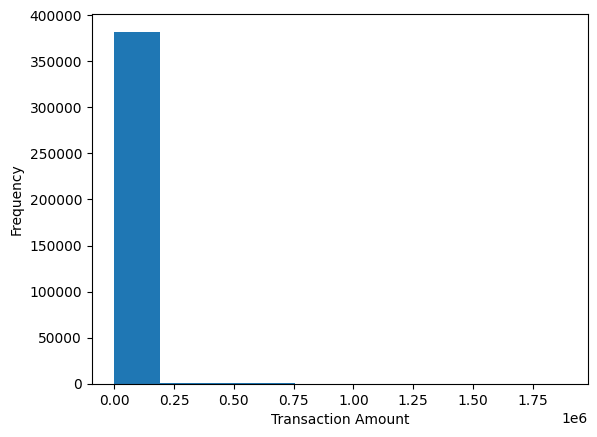

In [14]:
import matplotlib.pyplot as plt

plt.hist(df["Transaction_Amount"])
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.show()

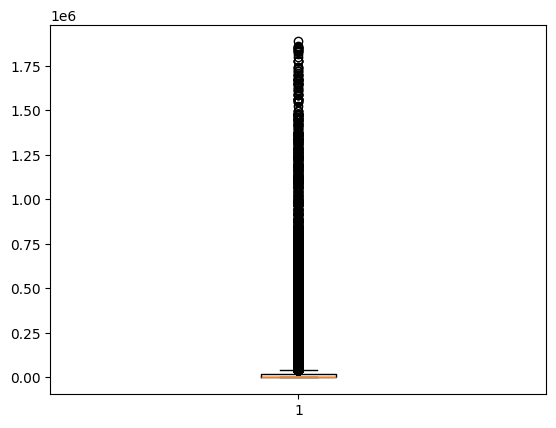

In [15]:
plt.boxplot(df["Transaction_Amount"])
plt.show()

In [16]:
Data_Preprocessing
Missing Value Handling
Duplicate Handling
Categorical Encoding
Date/Time Handling
Outlier Treatment
Skewness Treatment
Feature Scaling
Class Imbalance Handling

↓

SyntaxError: invalid character '↓' (U+2193) (3822731698.py, line 11)